In [2]:
from langgraph.graph import StateGraph,START,END
from langchain_openai import ChatOpenAI
from langchain_core.messages import BaseMessage,HumanMessage
from dotenv import load_dotenv
from typing import TypedDict
from langgraph.checkpoint.memory import InMemorySaver

In [3]:
# For Google LLM Model
from langchain_google_genai import ChatGoogleGenerativeAI

In [5]:
load_dotenv()

True

In [6]:
llm = ChatOpenAI(model="gpt-4o-mini")  # For OpenAI LLM Model
#llm=ChatGoogleGenerativeAI(             # For GoogleAI LLM Model
#    model="gemini-3.5-flash-lite",
#)


In [8]:
class JokeState(TypedDict):
    
    topic: str
    joke:str
    explaination: str

In [9]:
def generate_joke(state: JokeState):
    prompt = f"Generate a joke on the topic  {state['topic'] }"
    response = llm.invoke(prompt).content
    
    return {'joke' : response}
    
    

In [10]:
def generate_explaination(state: JokeState):
    prompt = f'Generate a explaination on the joke {state["joke"]}'
    response = llm.invoke(prompt).content
    
    return {'explaination' : response}

In [11]:
graph = StateGraph(JokeState)

graph.add_node('generate_joke',generate_joke)
graph.add_node('generate_explaination',generate_explaination)

graph.add_edge(START,'generate_joke')
graph.add_edge('generate_joke','generate_explaination')
graph.add_edge('generate_explaination',END)

checkpoint = InMemorySaver()

workflow = graph.compile(checkpointer=checkpoint)


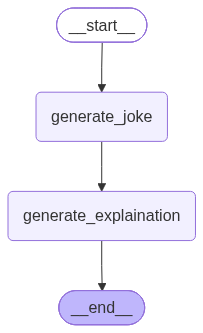

In [12]:
workflow

In [13]:
config1={"configurable" : {"thread_id" : "1"}}
workflow.invoke({"topic" : 'Football'}, config=config1)

{'topic': 'Football',
 'joke': 'Why did the football team go to the bank? \n\nBecause they wanted to get their quarterback!',
 'explaination': 'The joke "Why did the football team go to the bank? Because they wanted to get their quarterback!" is a clever play on words, involving a pun that relies on the double meaning of "quarterback."\n\n1. **Football Context**: In American football, a "quarterback" is a key player who leads the team\'s offense, calls the plays, and makes strategic decisions. The quarterback is typically responsible for throwing the ball to receivers or handing it off to other players.\n\n2. **Banking Context**: The joke sets up a situation where a football team is going to the bank, which is a common place for people to go to manage their money. The punchline reveals that they are there to "get their quarterback," playing on the word "quarterback" as if it refers to a monetary transaction.\n\n3. **Pun**: The humor comes from the unexpected twist in the punchline. Ins

In [14]:
workflow.get_state(config1)

StateSnapshot(values={'topic': 'Football', 'joke': 'Why did the football team go to the bank? \n\nBecause they wanted to get their quarterback!', 'explaination': 'The joke "Why did the football team go to the bank? Because they wanted to get their quarterback!" is a clever play on words, involving a pun that relies on the double meaning of "quarterback."\n\n1. **Football Context**: In American football, a "quarterback" is a key player who leads the team\'s offense, calls the plays, and makes strategic decisions. The quarterback is typically responsible for throwing the ball to receivers or handing it off to other players.\n\n2. **Banking Context**: The joke sets up a situation where a football team is going to the bank, which is a common place for people to go to manage their money. The punchline reveals that they are there to "get their quarterback," playing on the word "quarterback" as if it refers to a monetary transaction.\n\n3. **Pun**: The humor comes from the unexpected twist in

In [15]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'Football', 'joke': 'Why did the football team go to the bank? \n\nBecause they wanted to get their quarterback!', 'explaination': 'The joke "Why did the football team go to the bank? Because they wanted to get their quarterback!" is a clever play on words, involving a pun that relies on the double meaning of "quarterback."\n\n1. **Football Context**: In American football, a "quarterback" is a key player who leads the team\'s offense, calls the plays, and makes strategic decisions. The quarterback is typically responsible for throwing the ball to receivers or handing it off to other players.\n\n2. **Banking Context**: The joke sets up a situation where a football team is going to the bank, which is a common place for people to go to manage their money. The punchline reveals that they are there to "get their quarterback," playing on the word "quarterback" as if it refers to a monetary transaction.\n\n3. **Pun**: The humor comes from the unexpected twist i

In [19]:
config2={"configurable" : {"thread_id" : "2"}}
workflow.invoke({"topic" : 'Cricket'}, config=config2)

{'topic': 'Cricket',
 'joke': 'Why do cricket players never get lost?\n\nBecause they always follow the "pitch"!',
 'explaination': 'The joke "Why do cricket players never get lost? Because they always follow the \'pitch\'!" plays on a clever double meaning of the word "pitch."\n\nIn the context of cricket, a "pitch" refers to the rectangular area of ground where the game is played. It\'s a defined space that serves as the central playing surface for bowling and batting, which makes it essential for the game. When the joke mentions cricket players never getting lost because they always follow the pitch, it humorously suggests that they are always aware of their surroundings on the field.\n\nOn the other hand, the term "pitch" can also mean "to throw" or to "set something down in a specific location." This wordplay invites listeners to think about being lost in a more general sense—implying that if you have a clear direction or a physical path (like a pitch), you won\'t get lost.\n\nMor

In [20]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'Cricket', 'joke': 'Why do cricket players never get lost?\n\nBecause they always follow the "pitch"!', 'explaination': 'The joke "Why do cricket players never get lost? Because they always follow the \'pitch\'!" plays on a clever double meaning of the word "pitch."\n\nIn the context of cricket, a "pitch" refers to the rectangular area of ground where the game is played. It\'s a defined space that serves as the central playing surface for bowling and batting, which makes it essential for the game. When the joke mentions cricket players never getting lost because they always follow the pitch, it humorously suggests that they are always aware of their surroundings on the field.\n\nOn the other hand, the term "pitch" can also mean "to throw" or to "set something down in a specific location." This wordplay invites listeners to think about being lost in a more general sense—implying that if you have a clear direction or a physical path (like a pitch), you won

#Time Travel   

In [22]:
workflow.get_state({"configurable" : {"thread_id" : "2","checkpoint_id" : "1f1d064c-8329-63b3-8000-4cacff6f1f86"}})

StateSnapshot(values={'topic': 'Cricket'}, next=('generate_joke',), config={'configurable': {'thread_id': '2', 'checkpoint_id': '1f1d064c-8329-63b3-8000-4cacff6f1f86'}}, metadata={'source': 'loop', 'step': 0, 'parents': {}}, created_at='2026-10-25T11:11:09.926085+00:00', parent_config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1d064c-8324-65cd-bfff-54ad21c252f8'}}, tasks=(PregelTask(id='24d13299-616f-8724-1ae5-e0b401566331', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result={'joke': 'Why did the cricket team bring string to the game? \n\nBecause they wanted to tie the score! 🏏😂'}),), interrupts=())